<a href="https://colab.research.google.com/github/Cain7564/Ademovil/blob/main/Proyecto3paralela.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/Labdata3-Proyecto3.zip" -d /content
%cd /content/Labdata3

Mounted at /content/drive
/content/Labdata3


In [ ]:
!nvidia-smi
!nproc
import tensorflow as tf
print(tf.__version__, tf.config.list_physical_devices('GPU'))

Wed Nov 18 03:28:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q psutil

In [ ]:
!mkdir -p ~/.kaggle && cp /content/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle
!kaggle datasets download -d grassknoted/asl-alphabet -p /content/Labdata3/data/raw
!unzip -q /content/Labdata3/data/raw/asl-alphabet.zip -d /content/Labdata3/data/raw
!ls /content/Labdata3/data/raw/asl_alphabet_train/asl_alphabet_train | head -5

cp: cannot stat '/content/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/grassknoted/asl-alphabet
License(s): GPL-2.0
100% 1.03G/1.03G [00:12<00:00, 87.3MB/s]

A
B
C
D
del


In [ ]:
%cd /content/Labdata3
!P3_SMOKE=1 python -u scripts/proyecto3_cuda.py
!rm -rf artifacts/cuda/* artifacts/cache/*

/content/Labdata3
TensorFlow 2.21.0 | CPU lógicos: 2 | GPUs visibles: 1
{
  "fecha": "2026-11-18 03:30:16",
  "so": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "cpu": "x86_64",
  "nucleos_fisicos": 1,
  "nucleos_logicos": 2,
  "ram_gb": 12.7,
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "cuda_build": "12.5.1",
  "cudnn_build": "9",
  "gpus_tf": [
    "/physical_device:GPU:0"
  ],
  "nvidia_smi": "Tesla T4, 580.82.07, 15360 MiB"
}

Wed Nov 18 03:30:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |     

In [ ]:
!sed -i 's/^CPU_RUNS_CONFIG_A_B = N_RUNS/CPU_RUNS_CONFIG_A_B = 1/' scripts/proyecto3_cuda.py
!sed -i 's/^BENCH_EPOCHS = 5/BENCH_EPOCHS = 3/' scripts/proyecto3_cuda.py
!grep -n "^BENCH_EPOCHS\|^N_RUNS\|^CPU_RUNS" scripts/proyecto3_cuda.py

52:BENCH_EPOCHS = 3         # épocas por corrida (sin EarlyStopping, para comparar tiempos)
53:N_RUNS = 3               # repeticiones por configuración (≥3 recomendado)
54:CPU_RUNS_CONFIG_A_B = 1   # bajar a 1-2 si la CPU es muy lenta (cada época ≈ 2-3 min)


In [ ]:
!nohup python -u scripts/proyecto3_cuda.py > corrida.log 2>&1 &

In [ ]:
!tail -n 15 corrida.log

| N/A   57C    P8             16W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+------------------------+----------------------+

+-----------------------------------------------------------------------------------------+
| Processes:                                                                              |
|  GPU   GI   CI              PID   Type   Process name                        GPU Memory |
|        ID   ID                                                               Usage      |
|=========================================================================================|
|  No running processes found                                                             |
+-----------------------------------------------------------------------------------------+
train=12,180  val=2,610  clases=29  pasos/época=191
W0000 00:00:1794972835.9499

In [ ]:
!nvidia-smi

Wed Nov 18 03:34:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P0             29W /   70W |     121MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!top -b -n 1 | head -15

top - 03:34:18 up 13 min,  0 user,  load average: 1.43, 1.18, 0.61
Tasks:  27 total,   1 running,  25 sleeping,   0 stopped,   1 zombie
%Cpu(s): 71.4 us, 28.6 sy,  0.0 ni,  0.0 id,  0.0 wa,  0.0 hi,  0.0 si,  0.0 st 
MiB Mem :  12975.5 total,   1674.2 free,   2468.9 used,   9176.7 buff/cache     
MiB Swap:      0.0 total,      0.0 free,      0.0 used.  10506.6 avail Mem 

    PID USER      PR  NI    VIRT    RES    SHR S  %CPU  %MEM     TIME+ COMMAND
   4393 root      20   0   10.2g   1.3g 824844 S  90.9  10.2   0:30.58 python3
      1 root      20   0     988    568    508 S   0.0   0.0   0:00.02 docker-+
      7 root      20   0 1259552  72848  48832 S   0.0   0.5   0:02.10 node
      9 root      20   0    7348   3592   3280 S   0.0   0.0   0:00.38 oom_mon+
     11 root      20   0    7348   2108   1808 S   0.0   0.0   0:00.00 run.sh
     12 root      20   0 1287196  36464  22856 S   0.0   0.3   0:00.40 kernel_+
     41 root      20   0    5724   2228   2108 S   0.0   0.0   0:00.03 ta

In [ ]:
!nvidia-smi > evidencias/fase2_gpu_cuda/nvidia_smi.txt

In [ ]:
!mkdir -p /content/drive/MyDrive/Labdata3_resultados
!cp -r artifacts reports evidencias corrida.log /content/drive/MyDrive/Labdata3_resultados/

In [ ]:
!ls -la artifacts/cuda reports/figures/cuda

artifacts/cuda:
total 28
drwxr-xr-x 2 root root 4096 Nov 18 03:35 .
drwxr-xr-x 5 root root 4096 Nov  4 23:52 ..
-rw-r--r-- 1 root root  386 Nov 18 03:33 env_info.json
-rw-r--r-- 1 root root  281 Nov 18 03:34 fase1_scaling_workers.csv
-rw-r--r-- 1 root root 1728 Nov 18 03:35 monitor_fase1_preparacion_final.csv
-rw-r--r-- 1 root root 6435 Nov 18 03:34 monitor_fase1_preparacion_scaling.csv

reports/figures/cuda:
total 528
drwxr-xr-x 2 root root  4096 Nov 18 03:32 .
drwxr-xr-x 3 root root  4096 Nov  4 23:52 ..
-rw-r--r-- 1 root root 42218 Nov 18 03:32 fase1_escalado_cpu.png
-rw-r--r-- 1 root root 66512 Nov 18 03:32 recursos_A_original_CPU.png
-rw-r--r-- 1 root root 68071 Nov 18 03:32 recursos_B_RAM_CPU.png
-rw-r--r-- 1 root root 71180 Nov 18 03:32 recursos_C_RAM_CUDA.png
-rw-r--r-- 1 root root 68251 Nov 18 03:32 recursos_D_RAM_CUDA_mixed.png
-rw-r--r-- 1 root root 56700 Nov 18 03:32 recursos_fase1_prep_cpu.png
-rw-r--r-- 1 root root 98327 Nov 18 03:32 speedup_por_fase.png
-rw-r--r-- 1 root

In [ ]:
!ps aux | grep proyecto3 | grep -v grep
!echo
!tail -n 40 corrida.log
!echo
!ls -la artifacts/cuda artifacts/cache

root        4393  131 18.9 11752936 2521832 ?    Sl   03:33   4:08 python3 -u scripts/proyecto3_cuda.py
-------- LOG --------
Wed Nov 18 03:33:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             16W /   70W |       3MiB /  15360MiB |      0%      Default |
|             

In [ ]:
%cd /content/Labdata3
!rm -rf artifacts/cuda/* artifacts/cache/*
!nohup python -u scripts/proyecto3_cuda.py > corrida.log 2>&1 &

/content/Labdata3


In [ ]:
!tail -n 20 corrida.log

In [ ]:
!top -b -n 1 | head -15
!free -h

top - 03:39:41 up 19 min,  0 user,  load average: 4.96, 3.27, 1.67
Tasks:  30 total,   2 running,  27 sleeping,   0 stopped,   1 zombie
%Cpu(s): 90.9 us,  4.5 sy,  0.0 ni,  4.5 id,  0.0 wa,  0.0 hi,  0.0 si,  0.0 st 
MiB Mem :  12975.5 total,    340.2 free,   4216.2 used,   8803.8 buff/cache     
MiB Swap:      0.0 total,      0.0 free,      0.0 used.   8759.3 avail Mem 

    PID USER      PR  NI    VIRT    RES    SHR S  %CPU  %MEM     TIME+ COMMAND
   6368 root      20   0   10.2g   1.3g 818304 S  72.7  10.1   1:16.51 python3
   4393 root      20   0   11.1g   2.4g 852144 S  63.6  18.8   6:52.79 python3
   8512 root      20   0  189116  21568   6460 R   9.1   0.2   0:00.01 nvidia-+
      1 root      20   0     988    568    508 S   0.0   0.0   0:00.03 docker-+
      7 root      20   0 1260720  74104  48868 S   0.0   0.6   0:03.09 node
      9 root      20   0    7348   3592   3280 S   0.0   0.0   0:00.58 oom_mon+
     11 root      20   0    7348   2108   1808 S   0.0   0.0   0:00.00 r

In [ ]:
!grep -E "·|Epoch|val_acc" corrida.log | tail -n 15

In [ ]:
!ps -eo pid,lstart,etime,args | grep python | grep -v grep

     64 Wed Nov 18 03:22:37 2026       19:02 [python3] <defunct>
     65 Wed Nov 18 03:22:37 2026       19:02 python3 /usr/local/bin/colab-fileshim.py
    133 Wed Nov 18 03:22:41 2026       18:58 /usr/bin/python3 /usr/local/bin/jupyter-server --debug --transport="ipc" --ip=172.28.0.12 --ServerApp.token= --port=9000 --FileContentsManager.root_dir=/ --FileContentsManager.allow_hidden=True --ServerApp.log_format="|%(levelname)s|%(message)s" --ServerApp.iopub_data_rate_limit=1e10 --MappingKernelManager.root_dir=/content
    984 Wed Nov 18 03:26:09 2026       15:29 /usr/bin/python3 -m colab_kernel_launcher -f /root/.local/share/jupyter/runtime/kernel-6ac695a6-b07e-42f9-89b1-fd398bf139de.json
   1466 Wed Nov 18 03:26:59 2026       14:40 bash -c tail -n +0 -F "/root/.config/Google/DriveFS/Logs/drive_fs.txt" | python3 /opt/google/drive/drive-filter.py > "/root/.config/Google/DriveFS/Logs/timeouts.txt" 
   1469 Wed Nov 18 03:26:59 2026       14:40 python3 /opt/google/drive/drive-filter.py
   43

In [ ]:
import subprocess, time, os
os.chdir("/content/Labdata3")

def vivos():
    return subprocess.run("ps -eo pid,args | grep '[p]ython3 -u scripts/proyecto3_cuda.py'",
                          shell=True, capture_output=True, text=True).stdout.strip()

subprocess.run("pkill -9 -f '[p]ython3 -u scripts/proyecto3_cuda.py'", shell=True); time.sleep(5)
assert vivos() == "", f"Siguen vivos:\n{vivos()}"

subprocess.run("rm -rf artifacts/cuda/* artifacts/cache/* reports/figures/cuda/* corrida.log", shell=True)

subprocess.Popen("nohup python3 -u scripts/proyecto3_cuda.py > corrida.log 2>&1 &", shell=True)
time.sleep(8)
print(vivos())

10792 python3 -u scripts/proyecto3_cuda.py


In [ ]:
!ps -eo pid,etime,args | grep "[p]royecto3"

In [ ]:
!pgrep -af "[p]ython3 -u scripts/proyecto3_cuda"
!grep -E "·|Epoch|workers|Preparación" /content/Labdata3/corrida.log | tail -n 12

10792 python3 -u scripts/proyecto3_cuda.py
workers= 1  run=1    11.08s    1098.9 img/s
workers= 1  run=2    10.36s    1175.9 img/s
workers= 1  run=3    10.61s    1148.1 img/s
workers= 2  run=1     8.88s    1371.3 img/s
workers= 2  run=2     6.58s    1852.1 img/s
workers= 2  run=3     8.75s    1392.5 img/s
 workers   mean   std  speedup_vs_1  eficiencia


In [ ]:
!pgrep -af "[p]ython3 -u scripts/proyecto3_cuda" || echo "TERMINÓ: no hay proceso activo"

10792 python3 -u scripts/proyecto3_cuda.py


In [ ]:
!grep -E "·|Epoch|Preparación" /content/Labdata3/corrida.log | tail -n 8
!ls /content/Labdata3/artifacts/cuda

Preparación en RAM (2 núcleos): 14.7s | X_train (12180, 64, 64, 3) float32 (571 MB) | X_val (2610, 64, 64, 3)
A_original_CPU · corrida 1/1
Epoch 1/3
env_info.json		   monitor_fase1_preparacion_final.csv
fase1_scaling_workers.csv  monitor_fase1_preparacion_scaling.csv


In [ ]:
!pgrep -af "[p]ython3 -u scripts/proyecto3_cuda"
!top -b -n 1 | head -15
!free -h

10792 python3 -u scripts/proyecto3_cuda.py
top - 03:46:07 up 25 min,  0 user,  load average: 3.39, 3.10, 2.18
Tasks:  27 total,   1 running,  25 sleeping,   0 stopped,   1 zombie
%Cpu(s): 81.0 us, 19.0 sy,  0.0 ni,  0.0 id,  0.0 wa,  0.0 hi,  0.0 si,  0.0 st 
MiB Mem :  12975.5 total,   1623.7 free,   3658.7 used,   8053.9 buff/cache     
MiB Swap:      0.0 total,      0.0 free,      0.0 used.   9316.8 avail Mem 

    PID USER      PR  NI    VIRT    RES    SHR S  %CPU  %MEM     TIME+ COMMAND
  10792 root      20   0   11.1g   2.4g 848788 S 100.0  18.7   4:09.11 python3
      1 root      20   0     988    568    508 S   0.0   0.0   0:00.05 docker-+
      7 root      20   0 1261380  75604  48868 S   0.0   0.6   0:04.13 node
      9 root      20   0    7348   3592   3280 S   0.0   0.0   0:00.83 oom_mon+
     11 root      20   0    7348   2108   1808 S   0.0   0.0   0:00.00 run.sh
     12 root      20   0 1287196  35628  22852 S   0.0   0.3   0:00.79 kernel_+
     41 root      20   0    57

In [ ]:
import time, subprocess
log = "/content/Labdata3/corrida.log"
ultimo = ""
while True:
    vivo = subprocess.run("pgrep -f '[p]ython3 -u scripts/proyecto3_cuda'", shell=True,
                          capture_output=True, text=True).stdout.strip()
    lineas = [l for l in open(log).read().splitlines() if "·" in l or "Epoch" in l]
    actual = lineas[-1] if lineas else "(sin avance)"
    if actual != ultimo:
        print(time.strftime("%H:%M:%S"), "→", actual); ultimo = actual
    if "C_RAM_CUDA" in actual:
        print(">>> Llegó a la GPU: tomen las capturas de nvidia-smi ahora"); break
    if not vivo:
        print(">>> El proceso terminó. Revisen speedup.csv y el final del log"); break
    time.sleep(120)

04:14:42 →                                              Fase 3 · Inferencia val.: B → D_RAM_CUDA_mixed      20.66         0.83        24.78
>>> El proceso terminó. Revisen speedup.csv y el final del log


In [ ]:
import os, subprocess
base = "/content/Labdata3/artifacts/cuda"
print(sorted(os.listdir(base)))
print(subprocess.run("pgrep -af '[p]ython3 -u scripts/proyecto3_cuda' || echo 'sin proceso activo'",
                     shell=True, capture_output=True, text=True).stdout)

['benchmark_runs.csv', 'benchmark_summary.csv', 'env_info.json', 'fase1_scaling_workers.csv', 'monitor_A_original_CPU_run1.csv', 'monitor_B_RAM_CPU_run1.csv', 'monitor_C_RAM_CUDA_run1.csv', 'monitor_C_RAM_CUDA_run2.csv', 'monitor_C_RAM_CUDA_run3.csv', 'monitor_D_RAM_CUDA_mixed_run1.csv', 'monitor_D_RAM_CUDA_mixed_run2.csv', 'monitor_D_RAM_CUDA_mixed_run3.csv', 'monitor_fase1_preparacion_final.csv', 'monitor_fase1_preparacion_scaling.csv', 'speedup.csv', 'transferencia_h2d.json', 'uso_recursos.csv']
sin proceso activo



In [ ]:
!mkdir -p /content/drive/MyDrive/Labdata3_resultados
!cp -r /content/Labdata3/artifacts /content/Labdata3/reports /content/Labdata3/evidencias /content/Labdata3/corrida.log /content/drive/MyDrive/Labdata3_resultados/

In [ ]:
import pandas as pd
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)
display(pd.read_csv(f"{base}/benchmark_summary.csv").round(3))
display(pd.read_csv(f"{base}/speedup.csv").round(2))
display(pd.read_csv(f"{base}/uso_recursos.csv").round(1))
print(open(f"{base}/transferencia_h2d.json").read())

,config,corridas,fit_media,fit_std,epoca_media,pred_media,val_acc,val_f1
0,A_original_CPU,1,787.083,NaN,262.361,20.505,0.645,0.638
1,B_RAM_CPU,1,779.118,NaN,259.706,20.658,0.704,0.698
2,C_RAM_CUDA,3,23.928,3.009,7.976,0.928,0.671,0.665
3,D_RAM_CUDA_mixed,3,14.420,0.564,4.807,0.834,0.659,0.648


,Comparación,Antes (s),Después (s),Speedup (×)
0,"Fase 1 · Preparación (1 pasada, train): 1 hilo → N núcleos",10.68,8.07,1.32
1,"Fase 2 · Entrenamiento: A (original, lee JPG c/época) → B (datos en RAM) [efecto de caché]",787.08,779.12,1.01
2,Fase 2 · Entrenamiento: B (RAM+CPU) → C_RAM_CUDA [efecto de CUDA],779.12,23.93,32.56
3,Fase 2 · Entrenamiento: A (original) → C_RAM_CUDA,787.08,23.93,32.89
4,Fase 3 · Inferencia val.: B → C_RAM_CUDA,20.66,0.93,22.25
5,TOTAL extremo a extremo: A → C_RAM_CUDA (prep. única + fit),787.08,38.62,20.38
6,Fase 2 · Entrenamiento: B (RAM+CPU) → D_RAM_CUDA_mixed [efecto de CUDA],779.12,14.42,54.03
7,Fase 2 · Entrenamiento: A (original) → D_RAM_CUDA_mixed,787.08,14.42,54.58
8,Fase 3 · Inferencia val.: B → D_RAM_CUDA_mixed,20.66,0.83,24.78
9,TOTAL extremo a extremo: A → D_RAM_CUDA_mixed (prep. única + fit),787.08,29.11,27.04


,config,mon_cpu_mean_%,mon_cpu_max_%,mon_cores_>50%,mon_ram_max_gb,mon_gpu_util_mean_%,mon_gpu_util_max_%,mon_gpu_mem_max_mb
0,A_original_CPU,93.7,100.0,2.0,3.3,0.0,0.0,121.0
1,B_RAM_CPU,91.8,100.0,2.0,4.1,0.0,0.0,121.0
2,C_RAM_CUDA,45.1,94.3,0.0,4.0,56.0,85.7,2169.0
3,D_RAM_CUDA_mixed,67.9,98.2,2.0,4.4,37.6,63.0,2179.0
4,Fase1_preparacion,75.6,100.0,2.0,2.9,0.0,0.0,121.0


{
  "MB": 570.9375,
  "t_h2d_s": 0.7571226538000702,
  "GB_por_s": 0.736414568426031
}


fase1_escalado_cpu.png


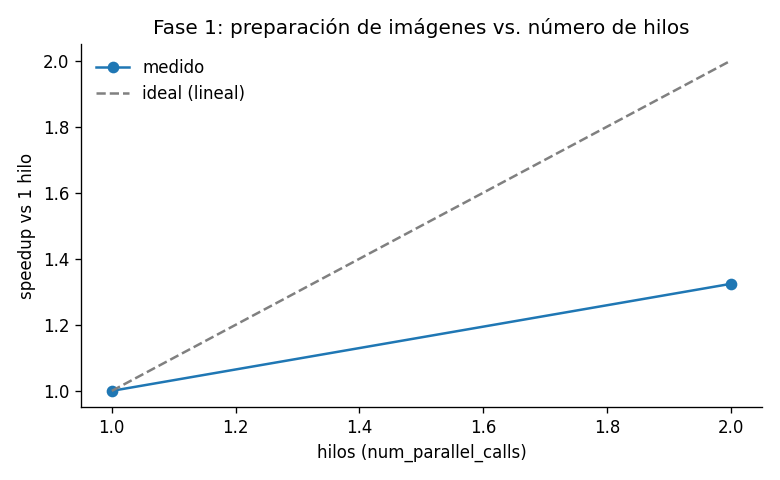

recursos_A_original_CPU.png


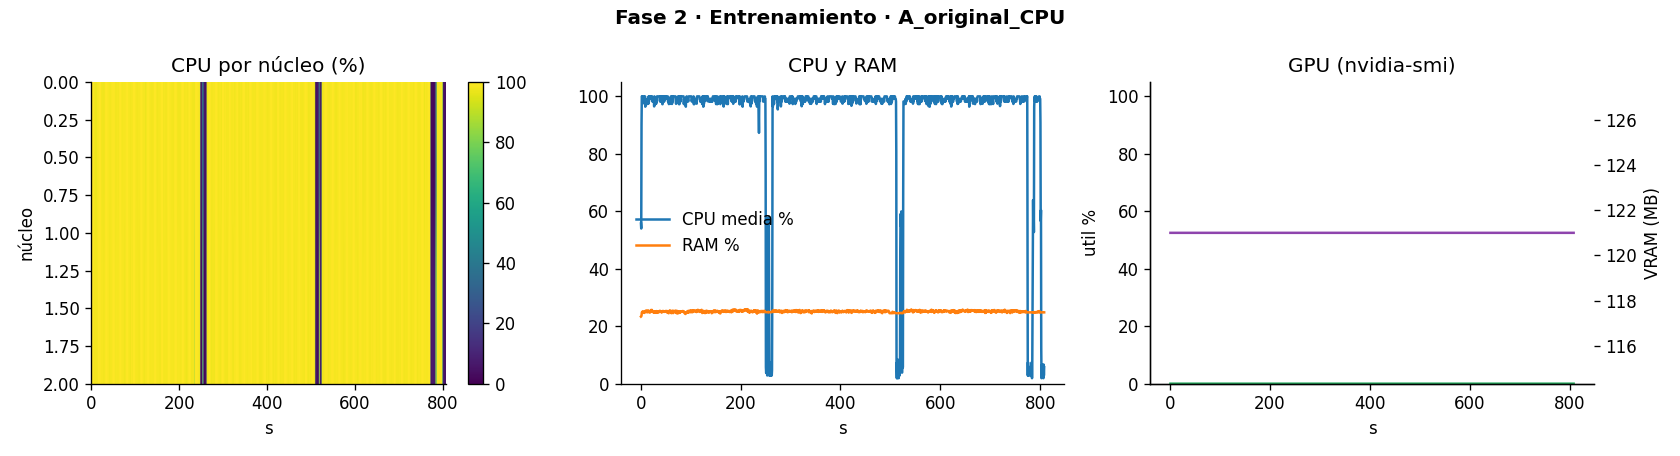

recursos_B_RAM_CPU.png


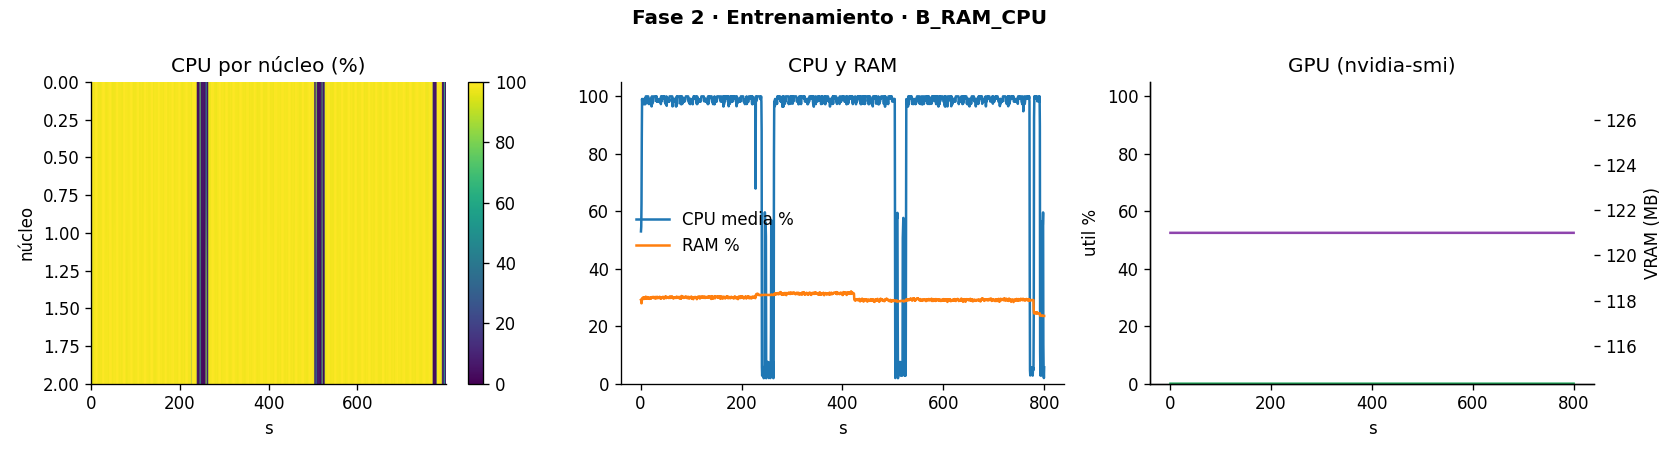

recursos_C_RAM_CUDA.png


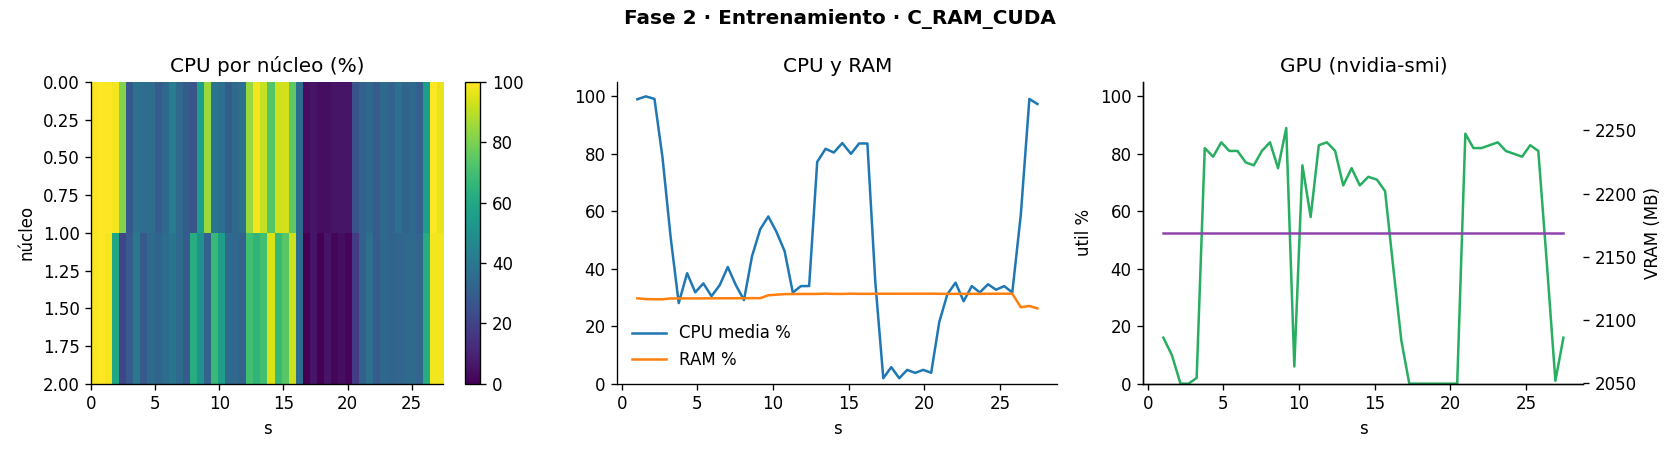

recursos_D_RAM_CUDA_mixed.png


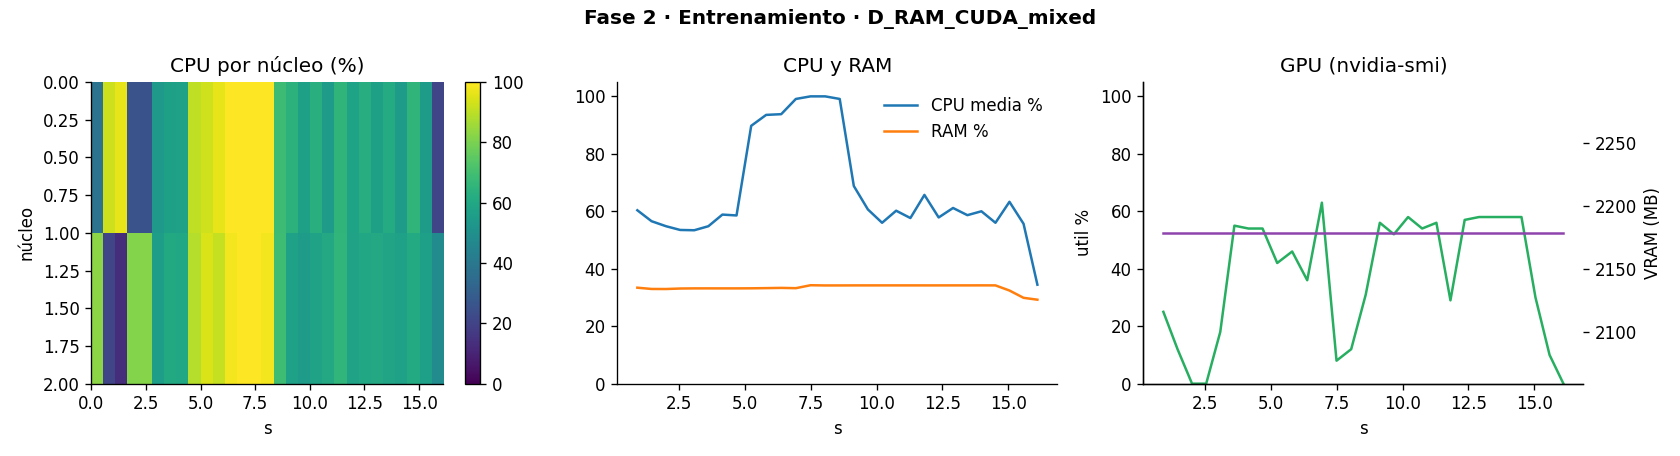

recursos_fase1_prep_cpu.png


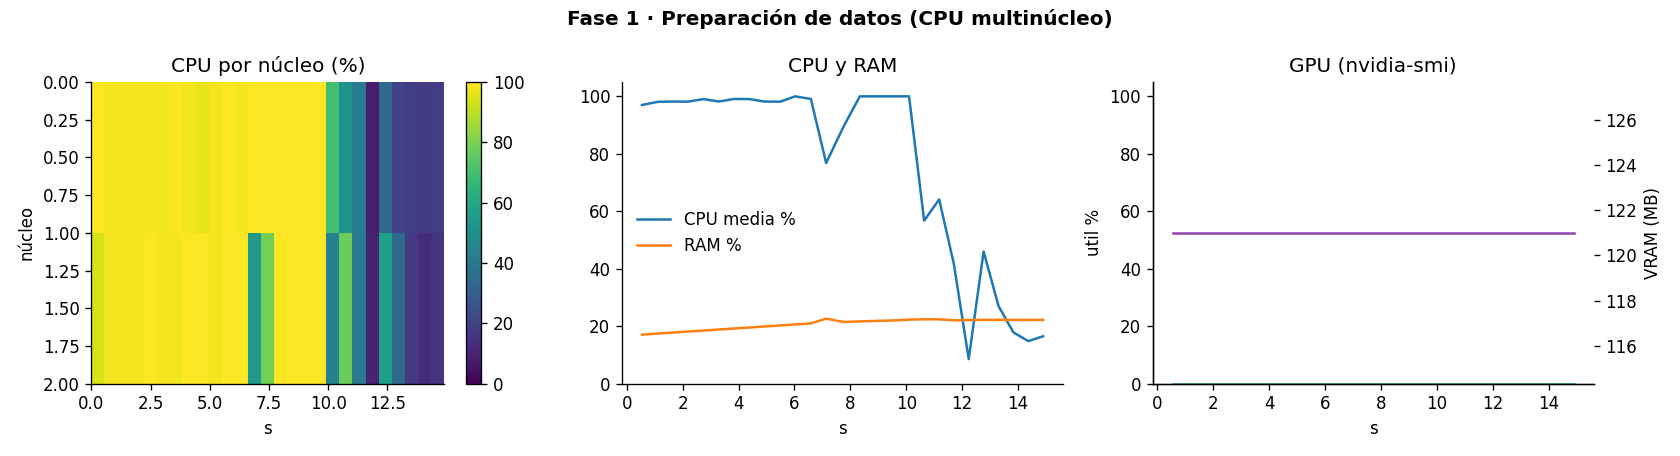

speedup_por_fase.png


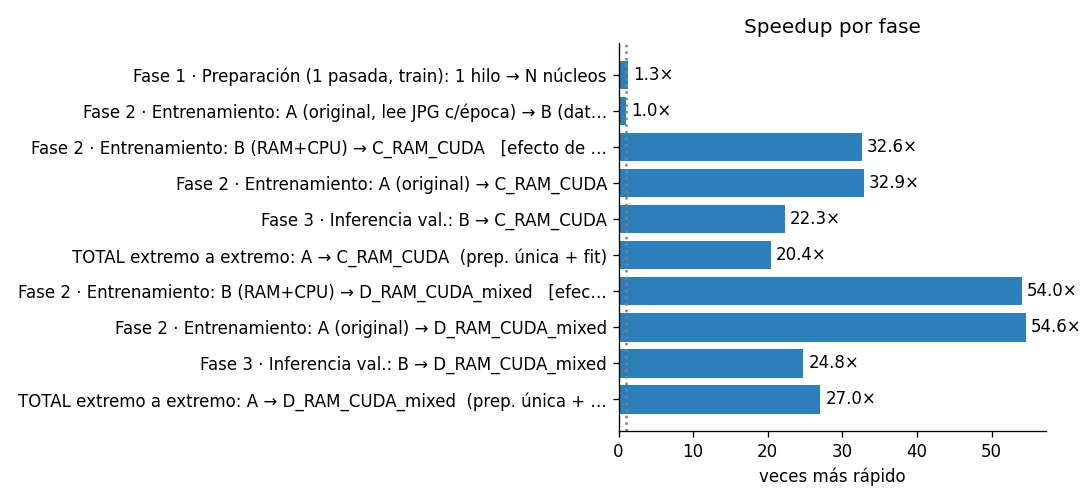

tiempos_entrenamiento.png


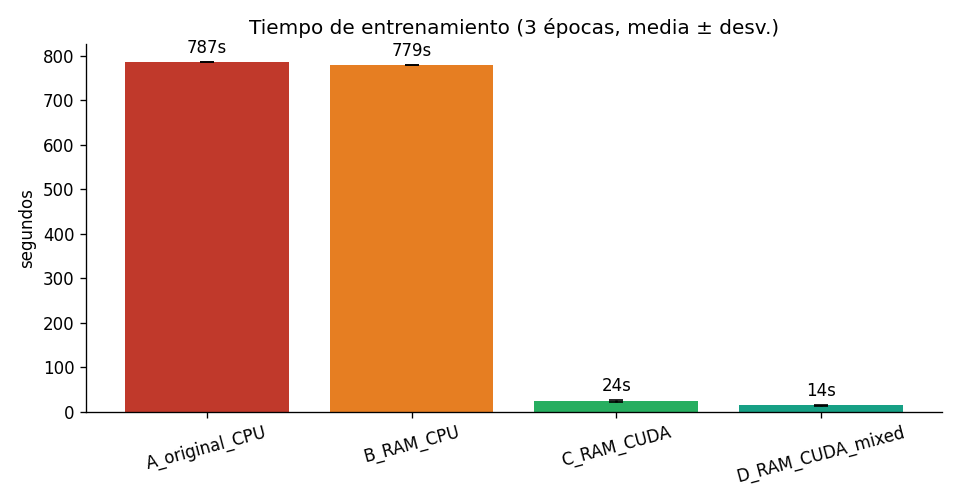

In [ ]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob("/content/Labdata3/reports/figures/cuda/*.png")):
    print(f.split("/")[-1]); display(Image(f))

# Ejecutar para montaje de todos los datos previamente realizados

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/Labdata3-Proyecto3.zip" -d /content
!cp -r /content/drive/MyDrive/Labdata3_resultados/artifacts /content/Labdata3/
!cp -r /content/drive/MyDrive/Labdata3_resultados/reports /content/Labdata3/
%cd /content/Labdata3

Mounted at /content/drive
/content/Labdata3


{
  "fecha": "2026-11-18 03:43:12",
  "so": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "cpu": "x86_64",
  "nucleos_fisicos": 1,
  "nucleos_logicos": 2,
  "ram_gb": 12.7,
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "cuda_build": "12.5.1",
  "cudnn_build": "9",
  "gpus_tf": [
    "/physical_device:GPU:0"
  ],
  "nvidia_smi": "Tesla T4, 580.82.07, 15360 MiB"
}

=== benchmark_summary.csv


,config,corridas,fit_media,fit_std,epoca_media,pred_media,val_acc,val_f1
0,A_original_CPU,1,787.083,NaN,262.361,20.505,0.645,0.638
1,B_RAM_CPU,1,779.118,NaN,259.706,20.658,0.704,0.698
2,C_RAM_CUDA,3,23.928,3.009,7.976,0.928,0.671,0.665
3,D_RAM_CUDA_mixed,3,14.420,0.564,4.807,0.834,0.659,0.648



=== speedup.csv


,Comparación,Antes (s),Después (s),Speedup (×)
0,"Fase 1 · Preparación (1 pasada, train): 1 hilo → N núcleos",10.684,8.068,1.324
1,"Fase 2 · Entrenamiento: A (original, lee JPG c/época) → B (datos en RAM) [efecto de caché]",787.083,779.118,1.010
2,Fase 2 · Entrenamiento: B (RAM+CPU) → C_RAM_CUDA [efecto de CUDA],779.118,23.928,32.561
3,Fase 2 · Entrenamiento: A (original) → C_RAM_CUDA,787.083,23.928,32.894
4,Fase 3 · Inferencia val.: B → C_RAM_CUDA,20.658,0.928,22.252
5,TOTAL extremo a extremo: A → C_RAM_CUDA (prep. única + fit),787.083,38.616,20.382
6,Fase 2 · Entrenamiento: B (RAM+CPU) → D_RAM_CUDA_mixed [efecto de CUDA],779.118,14.420,54.031
7,Fase 2 · Entrenamiento: A (original) → D_RAM_CUDA_mixed,787.083,14.420,54.583
8,Fase 3 · Inferencia val.: B → D_RAM_CUDA_mixed,20.658,0.834,24.777
9,TOTAL extremo a extremo: A → D_RAM_CUDA_mixed (prep. única + fit),787.083,29.108,27.040



=== uso_recursos.csv


,config,mon_cpu_mean_%,mon_cpu_max_%,mon_cores_>50%,mon_ram_max_gb,mon_gpu_util_mean_%,mon_gpu_util_max_%,mon_gpu_mem_max_mb
0,A_original_CPU,93.7,100.0,2.0,3.3,0.0,0.0,121.0
1,B_RAM_CPU,91.8,100.0,2.0,4.1,0.0,0.0,121.0
2,C_RAM_CUDA,45.1,94.3,0.0,4.0,56.0,85.7,2169.0
3,D_RAM_CUDA_mixed,67.9,98.2,2.0,4.4,37.6,63.0,2179.0
4,Fase1_preparacion,75.6,100.0,2.0,2.9,0.0,0.0,121.0



=== benchmark_runs.csv


,config,run,epocas,t_fit_s,t_epoca_s,t_pred_s,val_acc,val_f1_macro,mon_cpu_mean_%,mon_cpu_max_%,mon_cores_>50%,mon_ram_max_gb,mon_gpu_util_mean_%,mon_gpu_util_max_%,mon_gpu_mem_max_mb
0,A_original_CPU,1,3,787.083,262.361,20.505,0.645,0.638,93.668,100.00,2,3.293,0.000,0.0,121.0
1,B_RAM_CPU,1,3,779.118,259.706,20.658,0.704,0.698,91.797,100.00,2,4.082,0.000,0.0,121.0
2,C_RAM_CUDA,1,3,26.394,8.798,1.024,0.640,0.639,45.745,100.00,0,3.979,53.280,89.0,2169.0
3,C_RAM_CUDA,2,3,20.575,6.858,0.801,0.691,0.679,46.472,82.90,0,4.035,62.800,82.0,2169.0
4,C_RAM_CUDA,3,3,24.815,8.272,0.960,0.683,0.678,43.210,100.00,0,4.129,51.938,86.0,2169.0
5,D_RAM_CUDA_mixed,1,3,15.070,5.023,0.762,0.650,0.638,66.971,100.00,2,4.351,37.586,63.0,2179.0
6,D_RAM_CUDA_mixed,2,3,14.062,4.687,1.011,0.684,0.678,70.381,100.00,2,4.412,38.074,60.0,2179.0
7,D_RAM_CUDA_mixed,3,3,14.128,4.709,0.729,0.644,0.627,66.339,94.75,2,4.463,37.222,66.0,2179.0



=== fase1_scaling_workers.csv


,workers,run,segundos,img_por_seg
0,1,1,11.084,1098.881
1,1,2,10.358,1175.916
2,1,3,10.609,1148.055
3,2,1,8.882,1371.286
4,2,2,6.576,1852.132
5,2,3,8.747,1392.504


{
  "MB": 570.9375,
  "t_h2d_s": 0.7571226538000702,
  "GB_por_s": 0.736414568426031
}
fase1_escalado_cpu.png


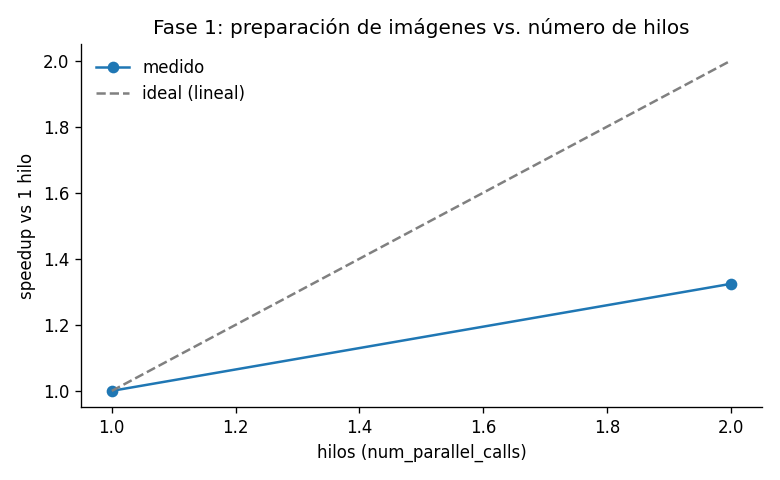

recursos_A_original_CPU.png


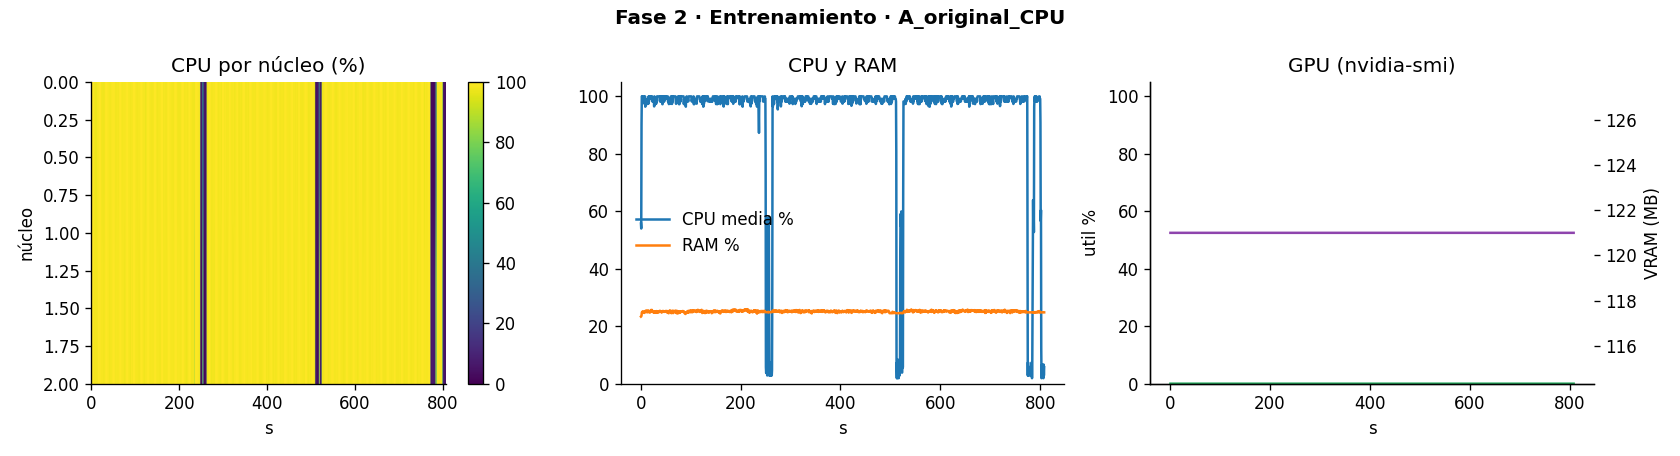

recursos_B_RAM_CPU.png


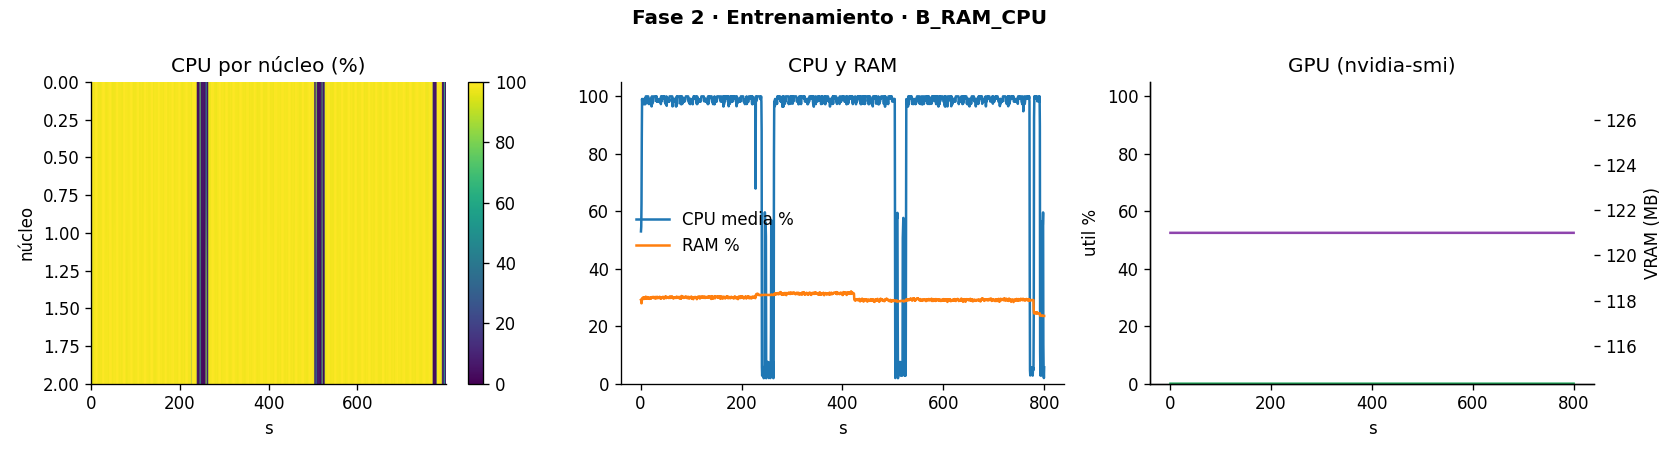

recursos_C_RAM_CUDA.png


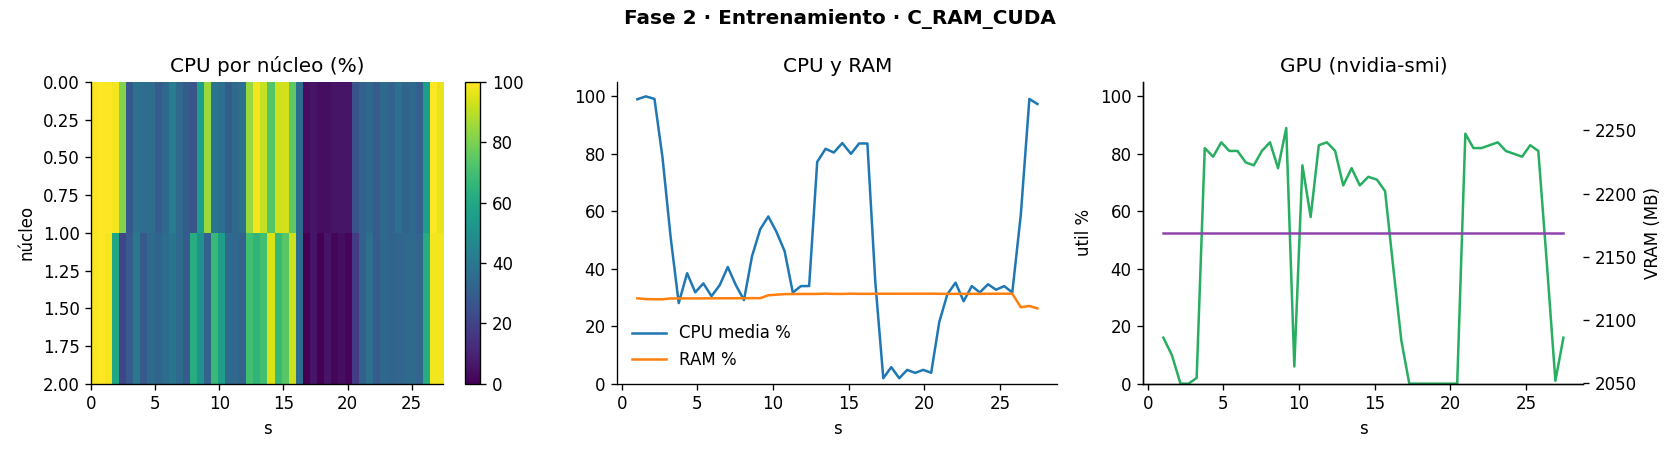

recursos_D_RAM_CUDA_mixed.png


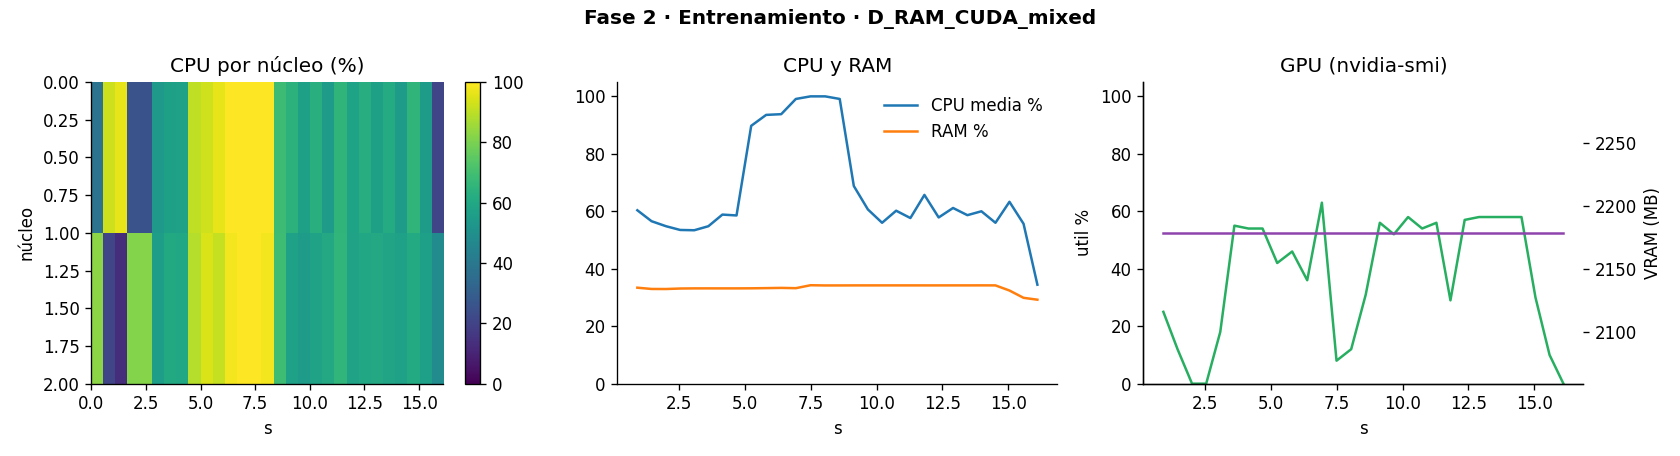

recursos_fase1_prep_cpu.png


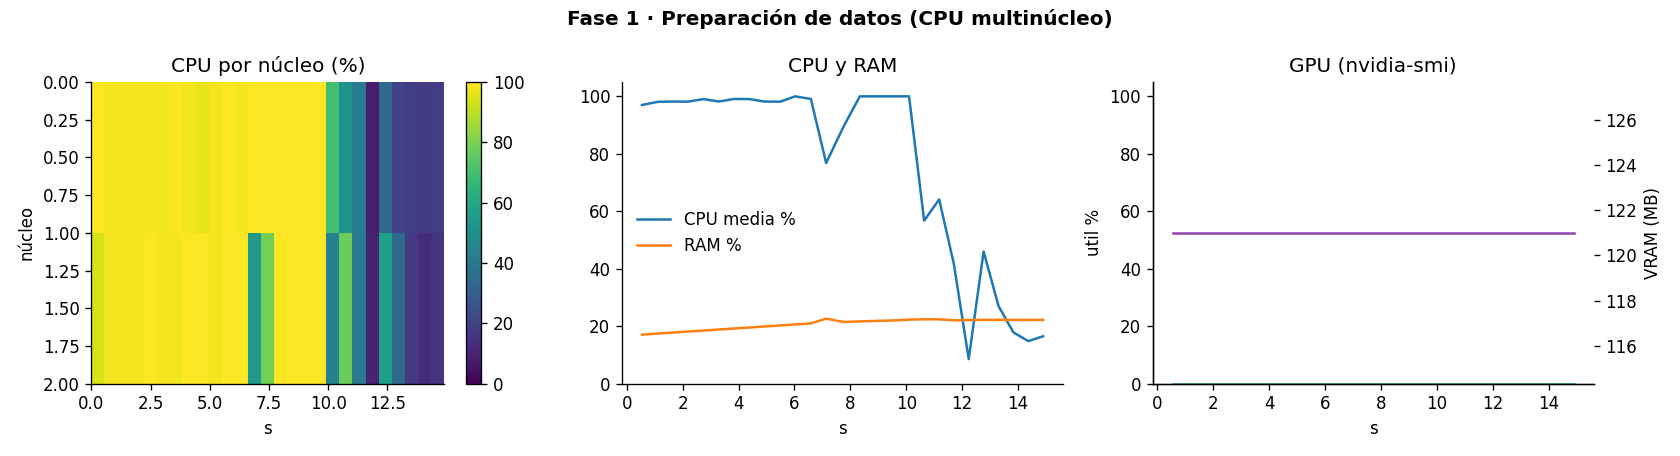

speedup_por_fase.png


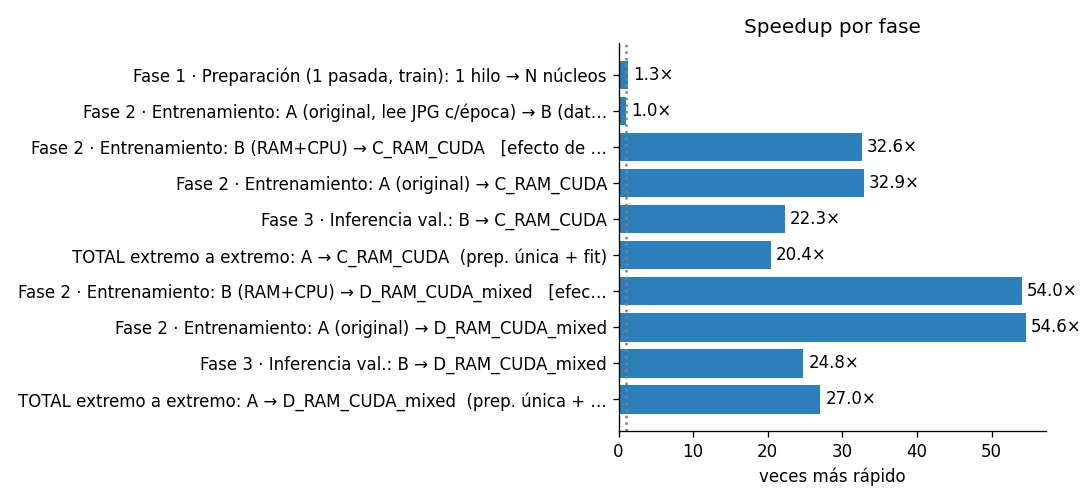

tiempos_entrenamiento.png


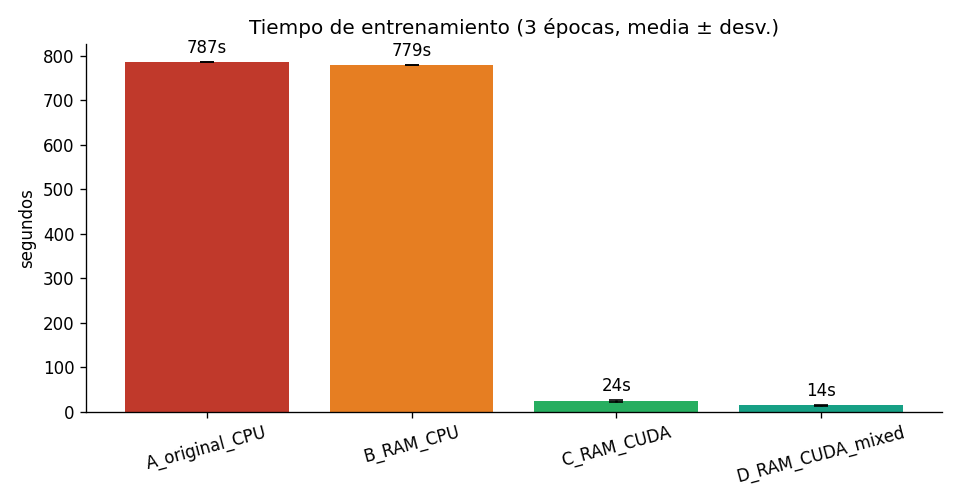

Exception in thread Thread-5 (fase1):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_3024/3774335473.py", line 49, in fase1
    for _ in (tf.data.Dataset.from_tensor_slices(paths)
              ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
              .map(dec, num_parallel_calls=tf.data.AUTOTUNE).batch(64).repeat(4)):
              ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/data/ops/iterator_ops.py", line 826, in __next__
    return self._next_internal()
           ~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/data/ops/iterator_ops.py", line 776, in _next_internal
    ret = gen_dataset_ops.itera


######## gpu_train · MUESTRA 1 ########
Wed Nov 18 05:06:17 AM UTC 2026
Wed Nov 18 05:06:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P0             67W /   70W |    2185MiB /  15360MiB |     65%      Default |
|                                         |                        

In [ ]:
import os, json, time, threading, subprocess, glob
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import Image, display

ROOT = Path("/content/Labdata3"); os.chdir(ROOT)
CUDA = ROOT / "artifacts/cuda"
assert not subprocess.run("pgrep -f '[p]ython3 -u scripts/proyecto3_cuda'", shell=True,
                          capture_output=True, text=True).stdout.strip(), "Hay un benchmark activo"

# ---------- 1. TODOS LOS RESULTADOS ----------
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 110)
print(open(CUDA / "env_info.json").read())
for f in ["benchmark_summary", "speedup", "uso_recursos", "benchmark_runs", "fase1_scaling_workers"]:
    print(f"\n=== {f}.csv"); display(pd.read_csv(CUDA / f"{f}.csv").round(3))
print(open(CUDA / "transferencia_h2d.json").read())
for f in sorted(glob.glob(str(ROOT / "reports/figures/cuda/*.png"))):
    print(Path(f).name); display(Image(f))

# ---------- datos para las corridas de evidencia ----------
adv = json.load(open("artifacts/metrics/resumen_avance.json"))
MEAN = np.asarray(adv["channel_mean_train"], np.float32); STD = np.asarray(adv["channel_std_train"], np.float32)
man = pd.read_csv("artifacts/metrics/particiones.csv")
tr = man[man.split.eq("train")].reset_index(drop=True)
paths = [str(ROOT / p) for p in tr.path]
y = tr.class_id.to_numpy(np.int32)
X = np.load(ROOT / "artifacts/cache/x_train_12180_2610.npy")
assert len(X) == len(y) == len(paths)

def muestrear(th, carpeta, prefijo, espera, cada, maxn):
    os.makedirs(carpeta, exist_ok=True); time.sleep(espera); n = 0
    while th.is_alive() and n < maxn:
        n += 1
        out = subprocess.run("date; nvidia-smi; echo; top -b -n 1 | head -12",
                             shell=True, capture_output=True, text=True).stdout
        open(f"{carpeta}/{prefijo}_{n}.txt", "w").write(out)
        print(f"\n######## {prefijo} · MUESTRA {n} ########\n{out}"); time.sleep(cada)
    th.join()

# ---------- 2. EVIDENCIA FASE 1: preparación en CPU (GPU debe verse en 0%) ----------
def dec(p):
    img = tf.image.resize(tf.io.decode_jpeg(tf.io.read_file(p), channels=3), (64, 64), method="area")
    return (tf.cast(img, tf.float32) / 255. - MEAN) / STD

def fase1():
    with tf.device("/CPU:0"):
        for _ in (tf.data.Dataset.from_tensor_slices(paths)
                  .map(dec, num_parallel_calls=tf.data.AUTOTUNE).batch(64).repeat(4)):
            pass

th = threading.Thread(target=fase1); th.start()
muestrear(th, "evidencias/fase1_cpu_multinucleo", "fase1_cpu", espera=4, cada=5, maxn=6)

# ---------- 3. EVIDENCIA FASE 2: entrenamiento en GPU ----------
def build():
    reg = keras.regularizers.l2(1e-4)
    i = keras.Input((64, 64, 3))
    u = layers.Rescaling(scale=STD, offset=MEAN)(i)
    u = keras.Sequential([layers.RandomRotation(.045, fill_mode="reflect"),
                          layers.RandomTranslation(.08, .08, fill_mode="reflect"),
                          layers.RandomZoom(.08, .08, fill_mode="reflect"),
                          layers.RandomContrast(.12),
                          layers.RandomBrightness(.12, value_range=(0, 1))])(u)
    x = layers.Normalization(mean=MEAN, variance=np.square(STD))(u)
    for f, d in ((32, .10), (64, .15)):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x); x = layers.SpatialDropout2D(d)(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x); x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(.35)(x)
    m = keras.Model(i, layers.Dense(29, activation="softmax")(x))
    m.compile(keras.optimizers.Adam(5e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def entrenar_gpu():
    with tf.device("/GPU:0"):
        build().fit(X, y, batch_size=64, epochs=15, verbose=0)

th = threading.Thread(target=entrenar_gpu); th.start()
muestrear(th, "evidencias/fase2_gpu_cuda", "gpu_train", espera=25, cada=8, maxn=8)

# ---------- 4. GUARDAR EN DRIVE ----------
subprocess.run("mkdir -p /content/drive/MyDrive/Labdata3_resultados && "
               "cp -r artifacts reports evidencias corrida.log /content/drive/MyDrive/Labdata3_resultados/",
               shell=True)
print("\n✅ Listo. Archivos de evidencia en evidencias/ y copia en Drive.")

In [ ]:
import os, json, time, threading, subprocess
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
ROOT = Path("/content/Labdata3"); os.chdir(ROOT)
assert (ROOT/"data/raw/asl_alphabet_train/asl_alphabet_train/A").exists(), "Falta el dataset JPG"

adv = json.load(open("artifacts/metrics/resumen_avance.json"))
MEAN = np.asarray(adv["channel_mean_train"], np.float32); STD = np.asarray(adv["channel_std_train"], np.float32)
man = pd.read_csv("artifacts/metrics/particiones.csv")
paths = [str(ROOT/p) for p in man[man.split.eq("train")].path]
assert all(os.path.exists(p) for p in paths[:50]), "Rutas de imágenes inválidas"

def dec(p):
    img = tf.image.resize(tf.io.decode_jpeg(tf.io.read_file(p), channels=3), (64, 64), method="area")
    return (tf.cast(img, tf.float32) / 255. - MEAN) / STD

def fase1():
    with tf.device("/CPU:0"):
        for _ in (tf.data.Dataset.from_tensor_slices(paths)
                  .map(dec, num_parallel_calls=tf.data.AUTOTUNE).batch(64).repeat(6)):
            pass

os.makedirs("evidencias/fase1_cpu_multinucleo", exist_ok=True)
th = threading.Thread(target=fase1); th.start(); time.sleep(4); n = 0
while th.is_alive() and n < 8:
    n += 1
    out = subprocess.run("date; nvidia-smi; echo; top -b -n 1 | head -12",
                         shell=True, capture_output=True, text=True).stdout
    open(f"evidencias/fase1_cpu_multinucleo/fase1_cpu_{n}.txt", "w").write(out)
    print(f"\n######## FASE 1 · MUESTRA {n} ########\n{out}"); time.sleep(5)
th.join()


######## FASE 1 · MUESTRA 1 ########
Wed Nov 18 05:20:18 AM UTC 2026
Wed Nov 18 05:20:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   70C    P0             31W /   70W |    2185MiB /  15360MiB |      0%      Default |
|                                         |                        |  

In [ ]:
!pip install -q kaggle
!kaggle datasets download -d grassknoted/asl-alphabet -p /content/Labdata3/data/raw
!unzip -q /content/Labdata3/data/raw/asl-alphabet.zip -d /content/Labdata3/data/raw
!rm /content/Labdata3/data/raw/asl-alphabet.zip
!ls /content/Labdata3/data/raw/asl_alphabet_train/asl_alphabet_train | head -5

Dataset URL: https://www.kaggle.com/datasets/grassknoted/asl-alphabet
License(s): GPL-2.0
100% 1.03G/1.03G [00:57<00:00, 19.1MB/s]

A
B
C
D
del
